Name: Ayoola Njoku, Nilav Ghosh

In [1]:
#Importing necessary libraries
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (AdaBoostClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import (StratifiedKFold, GroupKFold, LeaveOneGroupOut,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [2]:
# Read and load the training and test data
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")
sample_solution = pd.read_csv("sample_solution.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
train.output.value_counts(normalize=True)

Train shape: (4584, 670)
Test shape : (1732, 669)


output
1    0.844895
0    0.155105
Name: proportion, dtype: float64

In [3]:
##Checking how train and test subjects overlap
subj = pd.DataFrame({
    "train": train.subject.value_counts(),
    "test": test.subject.value_counts(),
}).fillna(0).astype(int)
subj["train_frac_0"] = train.groupby("subject").output.apply(lambda s: (s == 0).mean()).round(3)
unseen = subj.index[subj.train == 0].tolist()
print("Subjects only in test:", unseen,
      f"-> {test.subject.isin(unseen).mean():.0%} of test rows")
subj

Subjects only in test: ['E', 'J'] -> 54% of test rows


,train,test,train_frac_0
subject,,,
A,380,59,0.029
B,513,78,0.140
C,361,71,0.244
D,420,83,0.062
E,0,312,NaN
F,330,60,0.221
G,518,88,0.508
H,181,33,0.138
I,663,124,0.038


In [4]:
##Preprocessing: raw, per-subject normalised, and hybrid (normalised + subject one-hot) features
y = train["output"]
groups = train["subject"]
g_arr = groups.to_numpy(dtype=object)  # FLAML needs a plain numpy array for groups

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    return pd.get_dummies(X, columns=["state"], dtype=int)

X_raw = prep(train)
X_test_raw = prep(test).reindex(columns=X_raw.columns, fill_value=0)
const_cols = X_raw.columns[X_raw.nunique() <= 1]
X_raw = X_raw.drop(columns=const_cols)
X_test_raw = X_test_raw.drop(columns=const_cols)
sensor_cols = [c for c in X_raw.columns if c[0] in "xyz" and c[1:].isdigit()]

# z-score every sensor column within its subject (train + test rows, no labels)
both = pd.concat([X_raw, X_test_raw], ignore_index=True)
subj_all = pd.concat([train.subject, test.subject], ignore_index=True)
gb = both[sensor_cols].groupby(subj_all.values)
both[sensor_cols] = ((both[sensor_cols] - gb.transform("mean")) / gb.transform("std").replace(0, np.nan)).fillna(0)
X_norm = both.iloc[:len(train)].reset_index(drop=True)
X_test_norm = both.iloc[len(train):].reset_index(drop=True)

subj_onehot = pd.get_dummies(subj_all, prefix="subj", dtype=int).reindex(
    columns=[f"subj_{s}" for s in sorted(train.subject.unique())], fill_value=0)
both_hyb = pd.concat([both, subj_onehot], axis=1)
X_hyb = both_hyb.iloc[:len(train)].reset_index(drop=True)
X_test_hyb = both_hyb.iloc[len(train):].reset_index(drop=True)

known = test.subject.isin(train.subject.unique()).values
print(f"Dropped {len(const_cols)} constant columns -> {X_raw.shape[1]} features; "
      f"hybrid: {X_hyb.shape[1]} features; known-subject test rows: {known.mean():.1%}")

Dropped 108 constant columns -> 564 features; hybrid: 575 features; known-subject test rows: 45.7%


In [5]:
##Evaluation harness: stratified and GroupKFold AUC, leaderboard proxy, within-subject AUC
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
results = []

def evaluate(name, model, X=None):
    X = X_raw if X is None else X
    row = {"model": name}
    for cv_name, cv, kw in [("strat", skf, {}), ("group", gkf, {"groups": groups})]:
        s = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                           scoring=["roc_auc", "accuracy", "f1_macro"], **kw)
        row[f"{cv_name}_auc"] = s["test_roc_auc"].mean()
        row[f"{cv_name}_auc_std"] = s["test_roc_auc"].std()
        row[f"{cv_name}_acc"] = s["test_accuracy"].mean()
        row[f"{cv_name}_f1m"] = s["test_f1_macro"].mean()
    results.append(row)
    return pd.Series(row)

PRIOR = (y == 1).mean()
_sizes = pd.Series(g_arr).value_counts()
_all = [c for r in range(3, 8) for c in itertools.combinations(sorted(_sizes.index), r)
        if 0.45 <= _sizes[list(c)].sum() / len(g_arr) <= 0.60]
_rng = np.random.default_rng(RANDOM_STATE)
proxy_subsets = [_all[i] for i in _rng.choice(len(_all), 300, replace=False)]

def lb_proxy(p_known, p_unseen=None):
    """Mean pooled AUC when ~54% of rows (random subject groups) get p_unseen (default: the
    constant PRIOR) and the rest get out-of-fold p_known."""
    p_unseen = np.full(len(y), PRIOR) if p_unseen is None else np.asarray(p_unseen)
    return np.mean([roc_auc_score(y, np.where(np.isin(g_arr, s), p_unseen, p_known))
                    for s in proxy_subsets])

def within_subject_auc(p):
    """AUC inside each subject that has both classes."""
    return pd.Series({s: roc_auc_score(y[g_arr == s], p[g_arr == s])
                      for s in np.unique(g_arr) if y[g_arr == s].nunique() > 1})

In [6]:
###### Baseline Model ######
evaluate("majority baseline", DummyClassifier(strategy="most_frequent"))

model            majority baseline
strat_auc                      0.5
strat_auc_std                  0.0
strat_acc                 0.844895
strat_f1m                 0.457964
group_auc                      0.5
group_auc_std                  0.0
group_acc                 0.852051
group_f1m                  0.45784
dtype: object

In [7]:
###### AdaBoost Classifier ######

In [8]:
##Default AdaBoost (decision stumps, 50 rounds)
ada_default = AdaBoostClassifier(random_state=RANDOM_STATE)
evaluate("ada stumps, n=50, lr=1.0", ada_default)

model            ada stumps, n=50, lr=1.0
strat_auc                        0.677709
strat_auc_std                    0.022044
strat_acc                        0.847077
strat_f1m                        0.492495
group_auc                        0.497292
group_auc_std                     0.04032
group_acc                         0.84109
group_f1m                         0.45557
dtype: object

In [9]:
##Number of rounds, tree depth and learning rate (staged GroupKFold AUC)
def staged_curve(model, n_estimators):
    aucs = np.zeros(n_estimators)
    for tr_idx, va_idx in gkf.split(X_raw, y, groups):
        m = model.fit(X_raw.iloc[tr_idx], y.iloc[tr_idx])
        for i, score in enumerate(m.staged_decision_function(X_raw.iloc[va_idx])):
            aucs[i] += roc_auc_score(y.iloc[va_idx], score)
    return aucs / gkf.get_n_splits()

N = 100
curves = {}
for depth in [1, 2, 3]:
    for lr in [1.0, 0.3, 0.1]:
        m = AdaBoostClassifier(DecisionTreeClassifier(max_depth=depth),
                               n_estimators=N, learning_rate=lr, random_state=RANDOM_STATE)
        curves[(depth, lr)] = staged_curve(m, N)
        best = curves[(depth, lr)].argmax()
        print(f"depth={depth} lr={lr:<4} best grouped AUC={curves[(depth, lr)][best]:.4f} at n={best + 1}")

depth=1 lr=1.0  best grouped AUC=0.5144 at n=2
depth=1 lr=0.3  best grouped AUC=0.5239 at n=5
depth=1 lr=0.1  best grouped AUC=0.5241 at n=19
depth=2 lr=1.0  best grouped AUC=0.5130 at n=33
depth=2 lr=0.3  best grouped AUC=0.5143 at n=9
depth=2 lr=0.1  best grouped AUC=0.5503 at n=12
depth=3 lr=1.0  best grouped AUC=0.5428 at n=97
depth=3 lr=0.3  best grouped AUC=0.5505 at n=7
depth=3 lr=0.1  best grouped AUC=0.5328 at n=19


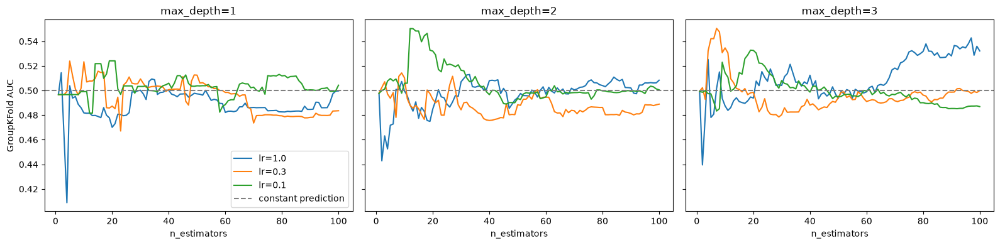

In [10]:
##Plot the staged learning curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, depth in zip(axes, [1, 2, 3]):
    for lr in [1.0, 0.3, 0.1]:
        ax.plot(np.arange(1, N + 1), curves[(depth, lr)], label=f"lr={lr}")
    ax.axhline(0.5, color="grey", ls="--", label="constant prediction")
    ax.set_title(f"max_depth={depth}")
    ax.set_xlabel("n_estimators")
axes[0].set_ylabel("GroupKFold AUC")
axes[0].legend()
plt.tight_layout()

In [11]:
##Confirm the best AdaBoost setting on both CV schemes
(best_depth, best_lr), best_curve = max(curves.items(), key=lambda kv: kv[1].max())
best_n = int(best_curve.argmax()) + 1
print(f"Best: depth={best_depth}, lr={best_lr}, n_estimators={best_n}")

ada_best = AdaBoostClassifier(DecisionTreeClassifier(max_depth=best_depth),
                              n_estimators=best_n, learning_rate=best_lr,
                              random_state=RANDOM_STATE)
evaluate(f"ada depth={best_depth}, n={best_n}, lr={best_lr}", ada_best)
pd.DataFrame(results).set_index("model").round(4)

Best: depth=3, lr=0.3, n_estimators=7


,strat_auc,strat_auc_std,strat_acc,strat_f1m,group_auc,group_auc_std,group_acc,group_f1m
model,,,,,,,,
majority baseline,0.5000,0.0000,0.8449,0.4580,0.5000,0.0000,0.8521,0.4578
"ada stumps, n=50, lr=1.0",0.6777,0.0220,0.8471,0.4925,0.4973,0.0403,0.8411,0.4556
"ada depth=3, n=7, lr=0.3",0.6648,0.0058,0.8484,0.4910,0.5505,0.0902,0.8495,0.4606


In [12]:
##Ranking on held-out subjects
gss_tr, gss_va = next(GroupKFold(n_splits=4).split(X_raw, y, groups))
ada_best.fit(X_raw.iloc[gss_tr], y.iloc[gss_tr])
va = pd.DataFrame({"y": y.iloc[gss_va].values, "subject": groups.iloc[gss_va].values,
                   "p": ada_best.predict_proba(X_raw.iloc[gss_va])[:, 1]})
print("Held-out subjects:", sorted(va.subject.unique()))
print(f"AUC on held-out subjects: {roc_auc_score(va.y, va.p):.3f}")
print("Within-subject AUC:", {s: round(roc_auc_score(d.y, d.p), 3) for s, d in va.groupby("subject")
                              if d.y.nunique() > 1})
print(f"Predicted P(class 1) ranges from {va.p.min():.3f} to {va.p.max():.3f}")

Held-out subjects: ['C', 'I']
AUC on held-out subjects: 0.455
Within-subject AUC: {'C': 0.452, 'I': 0.668}
Predicted P(class 1) ranges from 0.568 to 0.881


Features ever used: 30 / 564


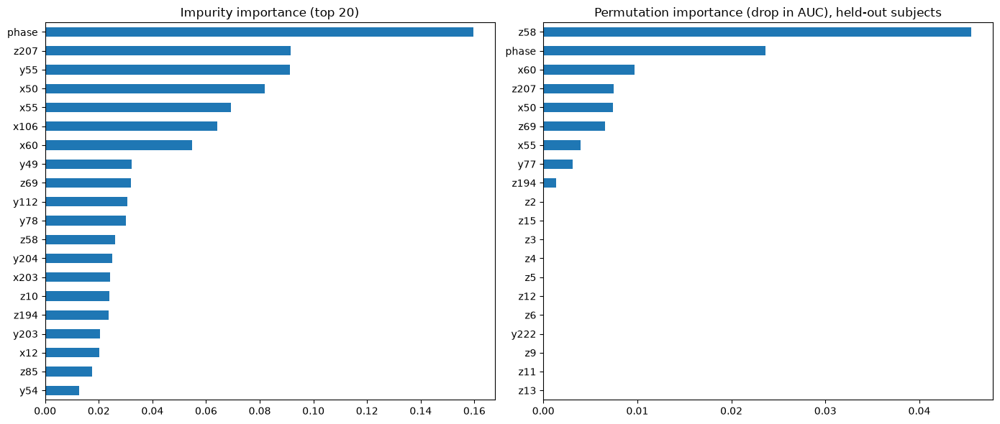

In [13]:
##AdaBoost feature importance: impurity vs permutation on held-out subjects
imp = pd.Series(ada_best.feature_importances_, index=X_raw.columns).sort_values(ascending=False)
print(f"Features ever used: {(imp > 0).sum()} / {len(imp)}")

perm = permutation_importance(ada_best, X_raw.iloc[gss_va], y.iloc[gss_va],
                              scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_raw.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(20)[::-1].plot.barh(ax=axes[0], title="Impurity importance (top 20)")
perm_imp.head(20)[::-1].plot.barh(ax=axes[1], title="Permutation importance (drop in AUC), held-out subjects")
plt.tight_layout()

In [14]:
# Train AdaBoost on the entire training dataset and create the submission
ada_best.fit(X_raw, y)
submission = sample_solution.copy().astype({"output": float})
submission["output"] = ada_best.predict_proba(X_test_raw)[:, 1]
submission.to_csv("submission_adaboost_proba.csv", index=False)
submission.output.describe().round(3)

count    1732.000
mean        0.840
std         0.049
min         0.360
25%         0.845
50%         0.848
75%         0.881
max         0.881
Name: output, dtype: float64

In [15]:
###### Neural Network (MLP) ######

In [16]:
##MLP with ordinary (global) scaling
def mlp(hidden=(64,), alpha=1e-3):
    return MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, early_stopping=True,
                         max_iter=500, random_state=RANDOM_STATE)

evaluate("MLP (64), global scaling", make_pipeline(StandardScaler(), mlp()))

model            MLP (64), global scaling
strat_auc                        0.659518
strat_auc_std                    0.037018
strat_acc                        0.845113
strat_f1m                        0.527959
group_auc                         0.54741
group_auc_std                    0.031194
group_acc                        0.837382
group_f1m                        0.465531
dtype: object

In [17]:
##MLP with per-subject scaling (each subject's own train or test rows)
def per_subject_scale(X, subj):
    X = X.copy()
    g = X[sensor_cols].groupby(subj.values)
    mean = g.transform("mean")
    std = g.transform("std").replace(0, np.nan)
    X[sensor_cols] = ((X[sensor_cols] - mean) / std).fillna(0)
    return X

X_subj = per_subject_scale(X_raw, groups)
evaluate("MLP (64), per-subject scaling", make_pipeline(StandardScaler(), mlp()), X_subj)

model            MLP (64), per-subject scaling
strat_auc                              0.60982
strat_auc_std                          0.05211
strat_acc                             0.835079
strat_f1m                             0.488764
group_auc                             0.490663
group_auc_std                         0.063369
group_acc                             0.812648
group_f1m                             0.460281
dtype: object

In [18]:
##Network size and L2 regularisation (alpha)
res = pd.DataFrame(results).set_index("model")
use_subj = res.loc["MLP (64), per-subject scaling", "group_auc"] > res.loc["MLP (64), global scaling", "group_auc"]
X_best = X_subj if use_subj else X_raw
scaling = "per-subject" if use_subj else "global"
print("Using", scaling, "scaling")

grid = []
for hidden in [(16,), (64,), (128, 64)]:
    for alpha in [1e-4, 1e-2, 1.0]:
        s = evaluate(f"MLP {hidden}, alpha={alpha}, {scaling}",
                     make_pipeline(StandardScaler(), mlp(hidden, alpha)), X_best)
        grid.append({"hidden": str(hidden), "alpha": alpha,
                     "group_acc": s.group_acc, "group_auc": s.group_auc})

grid = pd.DataFrame(grid)
grid.pivot(index="hidden", columns="alpha", values="group_auc").round(3)

Using global scaling


alpha,0.0001,0.0100,1.0000
hidden,,,
"(128, 64)",0.590,0.544,0.568
"(16,)",0.517,0.516,0.526
"(64,)",0.551,0.550,0.560


In [19]:
##Pooled vs within-subject ranking on held-out subjects
best_row = grid.loc[grid.group_auc.idxmax()]
best_model = make_pipeline(StandardScaler(), mlp(eval(best_row.hidden), best_row.alpha))
print(f"Best: hidden={best_row.hidden}, alpha={best_row.alpha}, scaling={scaling}")

proba_1 = cross_val_predict(best_model, X_best, y, cv=gkf, groups=groups,
                            method="predict_proba", n_jobs=-1)[:, 1]
within = within_subject_auc(proba_1)
print(f"Pooled out-of-fold grouped AUC: {roc_auc_score(y, proba_1):.3f}")
print(f"Mean within-subject AUC:        {within.mean():.3f}")
within.round(3).rename("within-subject AUC (subject unseen)").to_frame().T

Best: hidden=(128, 64), alpha=0.0001, scaling=global
Pooled out-of-fold grouped AUC: 0.515
Mean within-subject AUC:        0.560


,A,B,C,D,F,G,H,I,L,M
within-subject AUC (subject unseen),0.763,0.61,0.534,0.566,0.595,0.504,0.406,0.454,0.732,0.438


Held-out subjects: ['C', 'I']


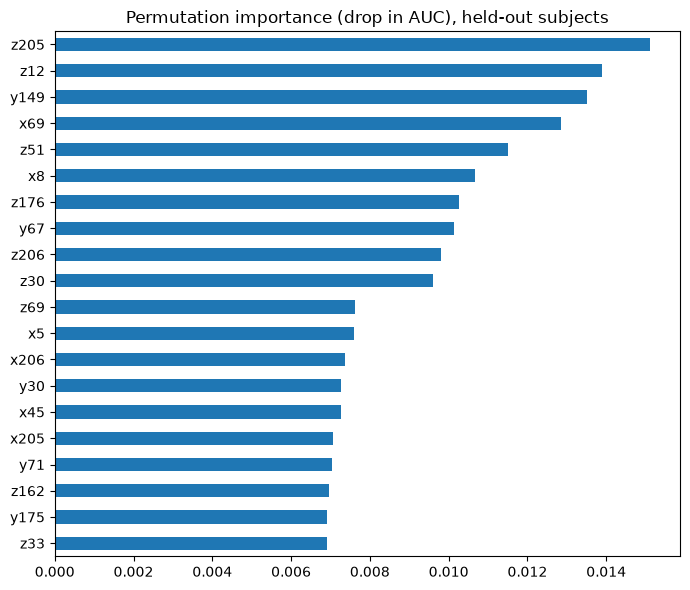

In [20]:
##MLP permutation importance on held-out subjects
tr_idx, va_idx = next(GroupKFold(n_splits=4).split(X_best, y, groups))
best_model.fit(X_best.iloc[tr_idx], y.iloc[tr_idx])
print("Held-out subjects:", sorted(groups.iloc[va_idx].unique()))

perm = permutation_importance(best_model, X_best.iloc[va_idx], y.iloc[va_idx],
                              scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_best.columns).sort_values(ascending=False)
perm_imp.head(20)[::-1].plot.barh(figsize=(7, 6),
                                  title="Permutation importance (drop in AUC), held-out subjects")
plt.tight_layout()

In [21]:
##PyTorch net with dropout, weight decay (L2) and subject-aware early stopping
import torch
from torch import nn
from joblib import Parallel, delayed
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit

def make_net(n_in, hidden, dropout):
    layers, d = [], n_in
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
        d = h
    layers.append(nn.Linear(d, 1))
    return nn.Sequential(*layers)

def fit_predict(X_tr, y_tr, g_tr, X_va, hidden, dropout, weight_decay, seed,
                es="subject", lr=1e-3, batch=128, max_epochs=200, patience=20, return_epoch=False):
    """Train one net and return P(class 1) for X_va. es="subject" early-stops on held-out
    training subjects; es="row" on random rows."""
    torch.set_num_threads(1)
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(X_tr)
    X_tr, X_va = scaler.transform(X_tr), scaler.transform(X_va)
    splitter = GroupShuffleSplit if es == "subject" else ShuffleSplit
    fit_idx, es_idx = next(splitter(n_splits=1, test_size=0.2, random_state=seed)
                           .split(X_tr, y_tr, g_tr if es == "subject" else None))
    t = lambda a: torch.tensor(a, dtype=torch.float32)
    Xf, yf, Xe, ye = t(X_tr[fit_idx]), t(y_tr[fit_idx]), t(X_tr[es_idx]), t(y_tr[es_idx])

    net = make_net(X_tr.shape[1], hidden, dropout)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    gen = torch.Generator().manual_seed(seed)
    best_loss, best_state, bad, best_epoch = np.inf, None, 0, 0
    for epoch in range(max_epochs):
        net.train()
        for idx in torch.randperm(len(Xf), generator=gen).split(batch):
            opt.zero_grad()
            loss_fn(net(Xf[idx]).squeeze(1), yf[idx]).backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            es_loss = loss_fn(net(Xe).squeeze(1), ye).item()
        if es_loss < best_loss - 1e-4:
            best_loss, bad, best_epoch = es_loss, 0, epoch + 1
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state)
    with torch.no_grad():
        proba = torch.sigmoid(net(t(X_va)).squeeze(1)).numpy()
    return (proba, best_epoch) if return_epoch else proba

In [22]:
##Dropout x weight decay grid (GroupKFold, 3 seeds)
Xv = X_raw.values.astype(np.float32)
yv = y.values.astype(np.float32)
gv = groups.values
folds = list(gkf.split(Xv, yv, gv))
SEEDS = [0, 1, 2]

def grouped_oof(configs):
    tasks = [(ci, s, k) for ci in range(len(configs)) for s in SEEDS for k in range(len(folds))]
    preds = Parallel(n_jobs=-1)(
        delayed(fit_predict)(Xv[folds[k][0]], yv[folds[k][0]], gv[folds[k][0]], Xv[folds[k][1]],
                             seed=s, **configs[ci])
        for ci, s, k in tasks)
    oof = np.zeros((len(configs), len(SEEDS), len(yv)))
    for (ci, s, k), p in zip(tasks, preds):
        oof[ci, s, folds[k][1]] = p
    return oof

def fold_scores(p):
    acc, f1, auc = [], [], []
    for _, va in folds:
        pred = (p[va] >= 0.5).astype(int)
        acc.append(accuracy_score(y.iloc[va], pred))
        f1.append(f1_score(y.iloc[va], pred, average="macro"))
        auc.append(roc_auc_score(y.iloc[va], p[va]))
    return np.mean(acc), np.mean(f1), np.mean(auc)

configs = [dict(hidden=(128, 64), dropout=d, weight_decay=w)
           for d in [0.0, 0.2, 0.4, 0.6] for w in [1e-4, 1e-2, 1e-1, 1.0]]
oof_nn = grouped_oof(configs)

rows = []
for c, o in zip(configs, oof_nn):
    s = np.array([fold_scores(p) for p in o])
    rows.append({"dropout": c["dropout"], "weight_decay": c["weight_decay"],
                 "group_acc": s[:, 0].mean(), "group_f1m": s[:, 1].mean(),
                 "group_auc": s[:, 2].mean(), "group_auc_seed_std": s[:, 2].std()})
torch_grid = pd.DataFrame(rows)
torch_grid.pivot(index="dropout", columns="weight_decay", values="group_auc").round(3)

weight_decay,0.0001,0.0100,0.1000,1.0000
dropout,,,,
0.0,0.513,0.513,0.512,0.507
0.2,0.508,0.504,0.502,0.505
0.4,0.505,0.505,0.504,0.503
0.6,0.488,0.483,0.486,0.496


,dropout,weight_decay,group_acc,group_f1m,group_auc,group_auc_seed_std
1,0.0,0.0100,0.8520,0.4626,0.5129,0.0088
0,0.0,0.0001,0.8520,0.4626,0.5126,0.0090
2,0.0,0.1000,0.8520,0.4626,0.5124,0.0090
4,0.2,0.0001,0.8521,0.4578,0.5084,0.0131
3,0.0,1.0000,0.8456,0.4561,0.5074,0.0027
7,0.2,1.0000,0.8469,0.4565,0.5053,0.0093


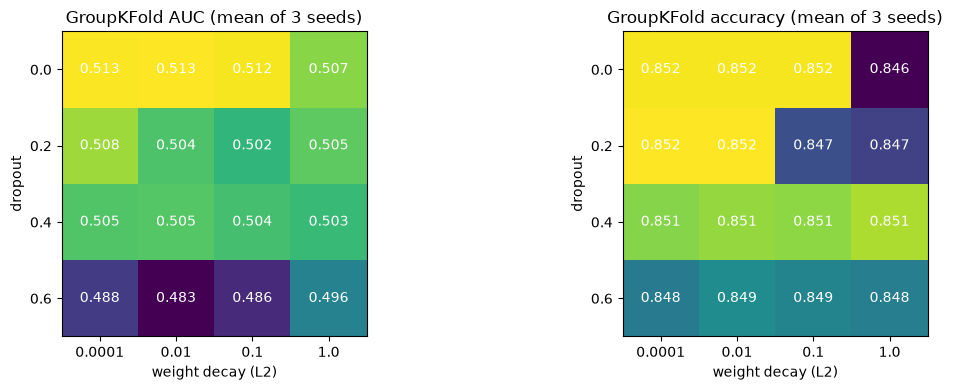

In [23]:
##Plot the dropout x weight decay grid
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "group_auc", "GroupKFold AUC"), (axes[1], "group_acc", "GroupKFold accuracy")]:
    piv = torch_grid.pivot(index="dropout", columns="weight_decay", values=col)
    ax.imshow(piv.values, cmap="viridis")
    ax.set_xticks(range(piv.shape[1]), piv.columns)
    ax.set_yticks(range(piv.shape[0]), piv.index)
    ax.set_xlabel("weight decay (L2)")
    ax.set_ylabel("dropout")
    ax.set_title(title + " (mean of 3 seeds)")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", color="w")
plt.tight_layout()
torch_grid.sort_values("group_auc", ascending=False).round(4).head(6)

In [24]:
##Which change caused the drop: early-stopping split vs dropout / weight decay
abl_cfgs = [dict(es=es, dropout=d, weight_decay=w)
            for es in ["subject", "row"] for d in [0.0, 0.4] for w in [1e-4, 1e-1]]
abl_tasks = [(ci, s, k) for ci in range(len(abl_cfgs)) for s in SEEDS for k in range(len(folds))]
abl_out = Parallel(n_jobs=-1)(
    delayed(fit_predict)(Xv[folds[k][0]], yv[folds[k][0]], gv[folds[k][0]], Xv[folds[k][1]],
                         hidden=(128, 64), seed=s, return_epoch=True, **abl_cfgs[ci])
    for ci, s, k in abl_tasks)
abl = pd.DataFrame([{**abl_cfgs[ci], "group_auc": roc_auc_score(y.iloc[folds[k][1]], p), "best_epoch": e}
                    for (ci, s, k), (p, e) in zip(abl_tasks, abl_out)])
abl.groupby(["es", "dropout", "weight_decay"]).agg(
    group_auc=("group_auc", "mean"), median_epoch=("best_epoch", "median"),
    max_epoch=("best_epoch", "max")).round(3)

group_auc  median_epoch  max_epoch
es      dropout weight_decay                                    
row     0.0     0.0001            0.546           4.0          5
                0.1000            0.550           4.0          5
        0.4     0.0001            0.542           5.0          7
                0.1000            0.546           5.0          7
subject 0.0     0.0001            0.513           2.0          2
                0.1000            0.512           2.0          2
        0.4     0.0001            0.505           2.0          5
                0.1000            0.504           2.0          5

In [25]:
##Pooled vs within-subject ranking for the best regularised net
best_cfg = torch_grid.group_auc.idxmax()
print("Best:", configs[best_cfg])
p_best = oof_nn[best_cfg].mean(axis=0)
print(f"Pooled OOF grouped AUC (seed-averaged): {roc_auc_score(y, p_best):.3f}")
print(f"Mean within-subject AUC:                {within_subject_auc(p_best).mean():.3f}")

Best: {'hidden': (128, 64), 'dropout': 0.0, 'weight_decay': 0.01}
Pooled OOF grouped AUC (seed-averaged): 0.396
Mean within-subject AUC:                0.510


In [26]:
##Neural net in the hybrid setup (known subjects, stratified CV)
Xh = X_hyb.values.astype(np.float32)
Xh_test = X_test_hyb.values.astype(np.float32)
sfolds = list(skf.split(Xh, yv))
hyb_cfgs = [dict(hidden=h, dropout=d, weight_decay=w)
            for h in [(64,), (128, 64)] for d in [0.0, 0.3] for w in [1e-2, 1e-1]]
hyb_tasks = [(ci, s, k) for ci in range(len(hyb_cfgs)) for s in SEEDS for k in range(len(sfolds))]
hyb_out = Parallel(n_jobs=-1)(
    delayed(fit_predict)(Xh[sfolds[k][0]], yv[sfolds[k][0]], gv[sfolds[k][0]], Xh[sfolds[k][1]],
                         seed=s, es="row", **hyb_cfgs[ci])
    for ci, s, k in hyb_tasks)
hyb_oof = np.zeros((len(hyb_cfgs), len(SEEDS), len(yv)))
for (ci, s, k), p in zip(hyb_tasks, hyb_out):
    hyb_oof[ci, s, sfolds[k][1]] = p

p_rf_ref = cross_val_predict(RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE),
                             Xh, y, cv=skf, method="predict_proba")[:, 1]
rows = {"constant (all rows)": {"auc": 0.5, "lb_proxy": lb_proxy(np.full(len(y), PRIOR))},
        "random forest reference": {"auc": roc_auc_score(y, p_rf_ref), "lb_proxy": lb_proxy(p_rf_ref)}}
for cfg, o in zip(hyb_cfgs, hyb_oof):
    p = o.mean(axis=0)
    rows[f"MLP {cfg['hidden']}, dropout={cfg['dropout']}, wd={cfg['weight_decay']}"] = {
        "auc": roc_auc_score(y, p), "lb_proxy": lb_proxy(p)}
hyb_results = pd.DataFrame(rows).T
hyb_results.sort_values("lb_proxy", ascending=False).round(4)

,auc,lb_proxy
random forest reference,0.8650,0.7352
"MLP (64,), dropout=0.3, wd=0.01",0.7859,0.6862
"MLP (64,), dropout=0.3, wd=0.1",0.7839,0.6835
"MLP (128, 64), dropout=0.0, wd=0.1",0.7859,0.6824
"MLP (128, 64), dropout=0.0, wd=0.01",0.7859,0.6818
"MLP (64,), dropout=0.0, wd=0.1",0.7787,0.6807
"MLP (64,), dropout=0.0, wd=0.01",0.7791,0.6801
"MLP (128, 64), dropout=0.3, wd=0.01",0.7810,0.6801
"MLP (128, 64), dropout=0.3, wd=0.1",0.7810,0.6777
constant (all rows),0.5000,0.5000


In [27]:
##Within-subject AUC: best hybrid MLP vs random forest
best_hyb = int(np.argmax([roc_auc_score(y, o.mean(axis=0)) for o in hyb_oof]))
cfg = hyb_cfgs[best_hyb]
print("Best MLP:", cfg)
pd.DataFrame({"MLP": within_subject_auc(hyb_oof[best_hyb].mean(axis=0)),
              "random forest": within_subject_auc(p_rf_ref)}).round(3).T

Best MLP: {'hidden': (64,), 'dropout': 0.3, 'weight_decay': 0.01}


,A,B,C,D,F,G,H,I,L,M
MLP,0.639,0.723,0.579,0.544,0.687,0.567,0.426,0.450,0.745,0.567
random forest,0.847,0.810,0.669,0.560,0.783,0.696,0.549,0.806,0.860,0.780


In [28]:
# Neural-net hybrid submission: MLP for known subjects, constant for E/J
p_test = np.mean([fit_predict(Xh, yv, gv, Xh_test[known], seed=s, es="row", **cfg) for s in SEEDS], axis=0)
nn_hybrid = sample_solution.copy().astype({"output": float})
nn_hybrid["output"] = PRIOR
nn_hybrid.loc[known, "output"] = p_test
nn_hybrid.to_csv("submission_nn_hybrid_proba.csv", index=False)
print(f"E/J rows: constant {PRIOR:.3f}")
nn_hybrid.output[known].groupby(test.subject[known].values).mean().round(3).rename("mean P(class 1), known subjects")

E/J rows: constant 0.845


A    0.938
B    0.843
C    0.759
D    0.910
F    0.797
G    0.568
H    0.855
I    0.925
K    0.933
L    0.892
M    0.793
Name: mean P(class 1), known subjects, dtype: float64

In [29]:
###### Random Forest Classifier ######

In [30]:
##Default random forest on raw features
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)
evaluate("rf default, raw", rf, X_raw)

model            rf default, raw
strat_auc               0.732604
strat_auc_std           0.021516
strat_acc               0.853403
strat_f1m               0.526932
group_auc               0.536172
group_auc_std           0.114587
group_acc               0.848169
group_f1m               0.461232
dtype: object

In [31]:
##Random forest on per-subject normalised features
evaluate("rf default, subject-norm", rf, X_norm)
pd.DataFrame(results).set_index("model").loc[["rf default, raw", "rf default, subject-norm"]].round(4)

,strat_auc,strat_auc_std,strat_acc,strat_f1m,group_auc,group_auc_std,group_acc,group_f1m
model,,,,,,,,
"rf default, raw",0.7326,0.0215,0.8534,0.5269,0.5362,0.1146,0.8482,0.4612
"rf default, subject-norm",0.8632,0.0076,0.8661,0.6631,0.5801,0.1462,0.8433,0.4649


In [32]:
##Tune max_features and min_samples_leaf (GroupKFold AUC)
best_rep = max(["raw", "subject-norm"],
               key=lambda r: pd.DataFrame(results).set_index("model").loc[f"rf default, {r}", "group_auc"])
X_best, X_test_best = (X_norm, X_test_norm) if best_rep == "subject-norm" else (X_raw, X_test_raw)
print("Using features:", best_rep)

grid = []
for mf in ["sqrt", 0.1, 0.3]:
    for leaf in [1, 5, 20]:
        m = RandomForestClassifier(n_estimators=300, max_features=mf, min_samples_leaf=leaf,
                                   n_jobs=-1, random_state=RANDOM_STATE)
        s = cross_validate(m, X_best, y, cv=gkf, groups=groups, n_jobs=-1, scoring=["roc_auc", "accuracy"])
        grid.append({"max_features": mf, "min_samples_leaf": leaf,
                     "group_auc": s["test_roc_auc"].mean(), "group_acc": s["test_accuracy"].mean()})
grid = pd.DataFrame(grid)
grid.pivot(index="max_features", columns="min_samples_leaf", values="group_auc").round(4)

Using features: subject-norm


min_samples_leaf,1,5,20
max_features,,,
0.1,0.5640,0.5883,0.5495
0.3,0.5247,0.5271,0.5102
sqrt,0.5801,0.5726,0.5481


In [33]:
##Confirm the tuned forest on both CV schemes
best = grid.loc[grid.group_auc.idxmax()]
best_params = {"max_features": best.max_features, "min_samples_leaf": int(best.min_samples_leaf)}
print("Best:", best_params)
rf_best = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE, **best_params)
rf_row = evaluate(f"rf tuned {best_params}, {best_rep}", rf_best, X_best)
rf_row

Best: {'max_features': 0.1, 'min_samples_leaf': 5}


model            rf tuned {'max_features': 0.1, 'min_samples_le...
strat_auc                                                 0.862774
strat_auc_std                                             0.009633
strat_acc                                                 0.866931
strat_f1m                                                 0.664246
group_auc                                                  0.58098
group_auc_std                                             0.146722
group_acc                                                 0.848652
group_f1m                                                  0.46339
dtype: object

In [34]:
##Extremely randomised trees (Extra Trees) with the same settings
et = ExtraTreesClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE, **best_params)
et_row = evaluate(f"extra trees {best_params}, {best_rep}", et, X_best)
pd.DataFrame(results).set_index("model").round(4)

,strat_auc,strat_auc_std,strat_acc,strat_f1m,group_auc,group_auc_std,group_acc,group_f1m
model,,,,,,,,
majority baseline,0.5000,0.0000,0.8449,0.4580,0.5000,0.0000,0.8521,0.4578
"ada stumps, n=50, lr=1.0",0.6777,0.0220,0.8471,0.4925,0.4973,0.0403,0.8411,0.4556
"ada depth=3, n=7, lr=0.3",0.6648,0.0058,0.8484,0.4910,0.5505,0.0902,0.8495,0.4606
"MLP (64), global scaling",0.6595,0.0370,0.8451,0.5280,0.5474,0.0312,0.8374,0.4655
"MLP (64), per-subject scaling",0.6098,0.0521,0.8351,0.4888,0.4907,0.0634,0.8126,0.4603
"MLP (16,), alpha=0.0001, global",0.6679,0.0176,0.8442,0.5391,0.5165,0.0667,0.8355,0.4665
"MLP (16,), alpha=0.01, global",0.6710,0.0180,0.8423,0.5415,0.5161,0.0635,0.8321,0.4614
"MLP (16,), alpha=1.0, global",0.6774,0.0213,0.8445,0.5403,0.5259,0.0662,0.8376,0.4608
"MLP (64,), alpha=0.0001, global",0.6606,0.0383,0.8445,0.5291,0.5506,0.0334,0.8370,0.4625


In [35]:
##Pooled vs within-subject ranking on unseen subjects
final_model = et if et_row.group_auc > rf_row.group_auc else rf_best
print("Model:", type(final_model).__name__)

oof = cross_val_predict(final_model, X_best, y, cv=gkf, groups=groups, method="predict_proba", n_jobs=-1)[:, 1]
within = within_subject_auc(oof)
print(f"Pooled out-of-fold grouped AUC: {roc_auc_score(y, oof):.3f}")
print(f"Mean within-subject AUC:        {within.mean():.3f}")
within.round(3).rename("within-subject AUC (subject unseen)").to_frame().T

Model: ExtraTreesClassifier
Pooled out-of-fold grouped AUC: 0.389
Mean within-subject AUC:        0.568


,A,B,C,D,F,G,H,I,L,M
within-subject AUC (subject unseen),0.804,0.609,0.483,0.593,0.534,0.533,0.345,0.704,0.571,0.5


In [36]:
##Do score levels track each subject's class rate?
levels = pd.DataFrame({"mean_pred_p1": pd.Series(oof).groupby(g_arr).mean(),
                       "true_rate_1": (y == 1).groupby(g_arr).mean()})
print(f"Correlation across subjects between mean predicted P(class 1) and true class-1 rate: "
      f"{levels.corr().iloc[0, 1]:.2f}")
levels.round(3).T

Correlation across subjects between mean predicted P(class 1) and true class-1 rate: -0.49


,A,B,C,D,F,G,H,I,K,L,M
mean_pred_p1,0.788,0.898,0.856,0.710,0.871,0.865,0.884,0.849,0.803,0.803,0.863
true_rate_1,0.971,0.860,0.756,0.938,0.779,0.492,0.862,0.962,1.000,0.912,0.709


Held-out subjects: ['C', 'I']
Top-20 overlap: ['x40', 'x47', 'y46', 'z47']


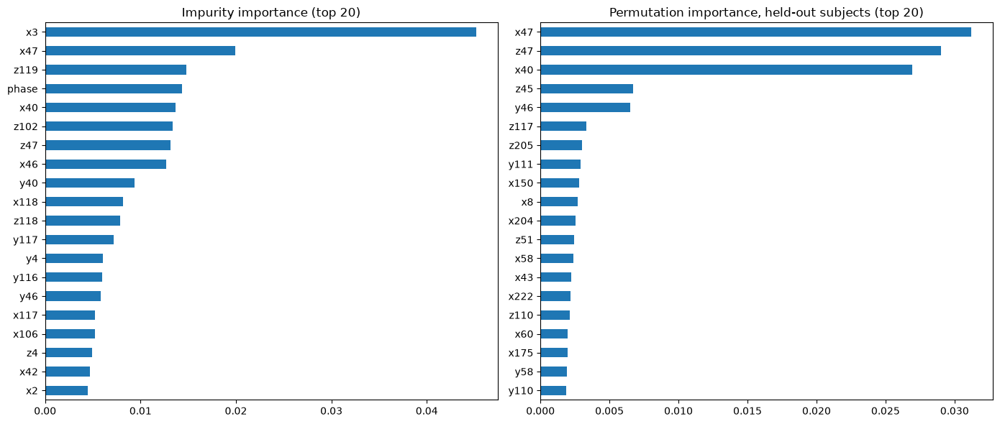

In [37]:
##Forest feature importance: impurity vs permutation on held-out subjects
tr_idx, va_idx = next(GroupKFold(n_splits=4).split(X_best, y, groups))
print("Held-out subjects:", sorted(groups.iloc[va_idx].unique()))
final_model.fit(X_best.iloc[tr_idx], y.iloc[tr_idx])

imp = pd.Series(final_model.feature_importances_, index=X_best.columns).sort_values(ascending=False)
perm = permutation_importance(final_model, X_best.iloc[va_idx], y.iloc[va_idx],
                              scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_best.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(20)[::-1].plot.barh(ax=axes[0], title="Impurity importance (top 20)")
perm_imp.head(20)[::-1].plot.barh(ax=axes[1], title="Permutation importance, held-out subjects (top 20)")
plt.tight_layout()
print("Top-20 overlap:", sorted(set(imp.head(20).index) & set(perm_imp.head(20).index)))

In [38]:
# Train the forest on the entire training dataset and create the submission
final_model.fit(X_best, y)
submission = sample_solution.copy().astype({"output": float})
submission["output"] = final_model.predict_proba(X_test_best)[:, 1]
submission.to_csv("submission_random_forest_proba.csv", index=False)
submission.output.describe().round(3)

count    1732.000
mean        0.840
std         0.122
min         0.085
25%         0.806
50%         0.857
75%         0.913
max         0.999
Name: output, dtype: float64

In [39]:
##Hybrid model: do known-subject test rows look like the training rows?
test_known = test[known]
print(f"Test rows from known subjects: {known.mean():.1%} ({known.sum()} rows)")
pd.concat({
    "train": train.phase.value_counts(normalize=True),
    "test, known subjects": test_known.phase.value_counts(normalize=True),
}, axis=1).sort_index().round(3)

Test rows from known subjects: 45.7% (791 rows)


,train,"test, known subjects"
phase,,
1,0.265,0.248
2,0.232,0.220
3,0.221,0.225
4,0.282,0.307


In [40]:
##Known subjects: subject-normalised features with and without the subject one-hot
candidates = {
    "subject-norm": (X_norm, X_test_norm),
    "subject-norm + subject id": (X_hyb, X_test_hyb),
}
rf_known = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
oof_known = {name: cross_val_predict(rf_known, X, y, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
             for name, (X, _) in candidates.items()}

known_results = pd.DataFrame(
    {"constant (all rows)": {"auc": 0.5, "lb_proxy": lb_proxy(np.full(len(y), PRIOR))}}
    | {name: {"auc": roc_auc_score(y, p), "lb_proxy": lb_proxy(p)} for name, p in oof_known.items()}).T
known_results.round(4)

,auc,lb_proxy
constant (all rows),0.5000,0.5000
subject-norm,0.8649,0.7326
subject-norm + subject id,0.8650,0.7352


In [41]:
##Within-subject AUC for the two known-subject feature sets
best_known = known_results.drop("constant (all rows)").lb_proxy.idxmax()
print(f"Best for known subjects: {best_known}")
pd.DataFrame({name: within_subject_auc(p) for name, p in oof_known.items()}).round(3).T

Best for known subjects: subject-norm + subject id


,A,B,C,D,F,G,H,I,L,M
subject-norm,0.842,0.804,0.662,0.572,0.782,0.692,0.580,0.804,0.861,0.78
subject-norm + subject id,0.847,0.810,0.669,0.560,0.783,0.696,0.549,0.806,0.860,0.78


In [42]:
# Random forest hybrid submission: forest for known subjects, constant for E/J
X_fit, X_test_fit = candidates[best_known]
rf_known.fit(X_fit, y)
hybrid = sample_solution.copy().astype({"output": float})
hybrid["output"] = PRIOR
hybrid.loc[known, "output"] = rf_known.predict_proba(X_test_fit[known])[:, 1]
hybrid.to_csv("submission_hybrid_proba.csv", index=False)
print(f"E/J rows: constant {PRIOR:.3f}")
hybrid.output[known].groupby(test_known.subject.values).mean().round(3).rename("mean P(class 1), known subjects")

E/J rows: constant 0.845


A    0.946
B    0.863
C    0.754
D    0.918
F    0.746
G    0.492
H    0.781
I    0.939
K    0.961
L    0.905
M    0.746
Name: mean P(class 1), known subjects, dtype: float64

In [43]:
###### AutoML (FLAML) ######

In [44]:
##AutoML helper (optimises ROC AUC)
from flaml import AutoML

TIME_UNSEEN = 300   # seconds of search on unseen subjects
TIME_KNOWN = 600    # seconds of search on known subjects
ESTIMATORS = ["lgbm", "xgboost", "rf", "extra_tree", "lrl1"]

def run_automl(X, split, time_budget, **kw):
    automl = AutoML()
    automl.fit(X, y, task="classification", metric="roc_auc", eval_method="cv", split_type=split,
               time_budget=time_budget, estimator_list=ESTIMATORS, seed=RANDOM_STATE, verbose=0, **kw)
    print(f"Best: {automl.best_estimator}  CV AUC = {1 - automl.best_loss:.4f}")
    print("Config:", {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                      for k, v in automl.best_config.items()})
    print("Best CV AUC per model family:",
          {k: round(1 - v, 4) for k, v in automl.best_loss_per_estimator.items() if v is not None and np.isfinite(v)})
    return automl

In [45]:
##AutoML on unseen subjects (raw features, GroupKFold)
automl_unseen = run_automl(X_raw, gkf, TIME_UNSEEN, groups=g_arr)

/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

Best: extra_tree  CV AUC = 0.5885
Config: {'n_estimators': 64, 'max_leaves': 27, 'max_features': 0.6746, 'criterion': np.str_('entropy')}
Best CV AUC per model family: {'lgbm': 0.5775, 'xgboost': 0.5823, 'rf': 0.5773, 'extra_tree': 0.5885, 'lrl1': 0.4949}


/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

In [46]:
##Re-score the AutoML choice with leave-one-subject-out
logo_model = clone(automl_unseen.model.estimator)
p_logo = cross_val_predict(logo_model, X_raw, y, cv=LeaveOneGroupOut(), groups=g_arr, method="predict_proba")[:, 1]

subj_auc = within_subject_auc(p_logo)
print(f"Leave-one-subject-out: pooled AUC = {roc_auc_score(y, p_logo):.3f}, "
      f"mean within-subject AUC = {subj_auc.mean():.3f}")
subj_auc.round(3).rename("within-subject AUC (held out)").to_frame().T

/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

Leave-one-subject-out: pooled AUC = 0.410, mean within-subject AUC = 0.563


/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

,A,B,C,D,F,G,H,I,L,M
within-subject AUC (held out),0.686,0.62,0.475,0.546,0.523,0.538,0.525,0.757,0.56,0.4


In [47]:
##AutoML in the hybrid setup (known subjects, stratified CV)
automl_known = run_automl(X_hyb, skf, TIME_KNOWN)

/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

Best: extra_tree  CV AUC = 0.8895
Config: {'n_estimators': 488, 'max_features': 0.0931, 'max_leaves': 414, 'criterion': np.str_('entropy')}
Best CV AUC per model family: {'lgbm': 0.8766, 'xgboost': 0.8665, 'rf': 0.8317, 'extra_tree': 0.8895, 'lrl1': 0.7548}


/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

In [48]:
##Compare AutoML with random forest, gradient boosting and blends
automl_model = clone(automl_known.model.estimator)
rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=800, early_stopping=False, max_leaf_nodes=31,
                                     l2_regularization=1.0, max_features=0.3, random_state=RANDOM_STATE)

oof_auto = {name: cross_val_predict(m, X_hyb, y, cv=skf, method="predict_proba")[:, 1]
            for name, m in [("random forest", rf), ("gradient boosting (800 rounds)", hgb),
                            (f"AutoML: {automl_known.best_estimator}", automl_model)]}
names = list(oof_auto)
oof_auto["blend rf + hgb"] = (oof_auto[names[0]] + oof_auto[names[1]]) / 2
oof_auto["blend rf + hgb + AutoML"] = (oof_auto[names[0]] + oof_auto[names[1]] + oof_auto[names[2]]) / 3

rows = {"constant (all rows)": {"auc": 0.5, "lb_proxy": lb_proxy(np.full(len(y), PRIOR))}}
rows.update({name: {"auc": roc_auc_score(y, p), "lb_proxy": lb_proxy(p)} for name, p in oof_auto.items()})
known_table = pd.DataFrame(rows).T
print("Correlation of OOF probabilities:")
print(pd.DataFrame({k: oof_auto[k] for k in names}).corr().round(3))
known_table.round(4)

/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

Correlation of OOF probabilities:
                                random forest  gradient boosting (800 rounds)  \
random forest                           1.000                           0.814   
gradient boosting (800 rounds)          0.814                           1.000   
AutoML: extra_tree                      0.962                           0.830   

                                AutoML: extra_tree  
random forest                                0.962  
gradient boosting (800 rounds)               0.830  
AutoML: extra_tree                           1.000  


,auc,lb_proxy
constant (all rows),0.5000,0.5000
random forest,0.8650,0.7352
gradient boosting (800 rounds),0.8678,0.7015
AutoML: extra_tree,0.8893,0.7517
blend rf + hgb,0.8689,0.7258
blend rf + hgb + AutoML,0.8812,0.7417


In [49]:
##Within-subject AUC: best known-subject model vs random forest
final_name = known_table.drop("constant (all rows)").lb_proxy.astype(float).idxmax()
print(f"Best for known subjects: {final_name}")
pd.DataFrame({final_name: within_subject_auc(oof_auto[final_name]),
              "random forest": within_subject_auc(oof_auto["random forest"])}).round(3).T

Best for known subjects: AutoML: extra_tree


,A,B,C,D,F,G,H,I,L,M
AutoML: extra_tree,0.892,0.872,0.699,0.591,0.809,0.715,0.695,0.858,0.90,0.839
random forest,0.847,0.810,0.669,0.560,0.783,0.696,0.549,0.806,0.86,0.780


In [ ]:
##AutoML model permutation importance (one stratified validation fold)
tr_idx, va_idx = next(skf.split(X_hyb, y))
imp_model = clone(automl_known.model.estimator).fit(X_hyb.iloc[tr_idx], y.iloc[tr_idx])
perm = permutation_importance(imp_model, X_hyb.iloc[va_idx], y.iloc[va_idx], scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_hyb.columns).sort_values(ascending=False)
perm_imp.head(20)[::-1].plot.barh(figsize=(7, 6), title=f"Permutation importance (drop in AUC), AutoML {automl_known.best_estimator}")
plt.tight_layout()
print(f"Features with importance > 0.002: {(perm_imp > 0.002).sum()}")
perm_imp.head(10).round(4)

/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

In [ ]:
# AutoML hybrid submission: best known-subject model, constant for E/J
models = {names[0]: rf, names[1]: hgb, names[2]: automl_model}
members = {"blend rf + hgb": names[:2], "blend rf + hgb + AutoML": names}.get(final_name, [final_name])
p_test_known = np.mean([clone(models[n]).fit(X_hyb, y).predict_proba(X_test_hyb[known])[:, 1] for n in members], axis=0)

automl_hybrid = sample_solution.copy().astype({"output": float})
automl_hybrid["output"] = PRIOR
automl_hybrid.loc[known, "output"] = p_test_known
automl_hybrid.to_csv("submission_automl_hybrid_proba.csv", index=False)
print(f"Model for known subjects: {final_name}; E/J rows: constant {PRIOR:.3f}")
automl_hybrid.output[known].groupby(test.subject[known].values).mean().round(3).rename("mean P(class 1), known subjects")

In [ ]:
##What should unseen subjects E and J get? Constant vs model probabilities (leave-one-subject-out)
unseen_models = {
    "Extra Trees (AutoML known-subject config, raw features)": clone(automl_known.model.estimator),
    "random forest (raw)": RandomForestClassifier(n_estimators=500, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "kNN, k=50": make_pipeline(StandardScaler(), KNeighborsClassifier(50)),
    "LDA, shrinkage": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")),
    "MLP (64,), alpha=1": make_pipeline(StandardScaler(), MLPClassifier((64,), alpha=1.0, early_stopping=True,
                                                                       max_iter=500, random_state=RANDOM_STATE)),
}
p_known_best = oof_auto[final_name]
p_unseen = {name: cross_val_predict(m, X_raw, y, cv=LeaveOneGroupOut(), groups=g_arr, method="predict_proba")[:, 1]
            for name, m in unseen_models.items()}
fill_table = pd.DataFrame(
    {f"constant {PRIOR:.3f}": {"lb_proxy": lb_proxy(p_known_best), "within_subject_auc": 0.5}}
    | {name: {"lb_proxy": lb_proxy(p_known_best, p), "within_subject_auc": within_subject_auc(p).mean()}
       for name, p in p_unseen.items()}).T
fill_table.sort_values("lb_proxy", ascending=False).round(4)

In [ ]:
# Variant submission: same known-subject probabilities, Extra Trees (raw) for E/J (scored 0.68)
et_raw = clone(automl_known.model.estimator).fit(X_raw, y)
variant = automl_hybrid.copy()
variant.loc[~known, "output"] = et_raw.predict_proba(X_test_raw[~known])[:, 1]
variant.to_csv("submission_automl_hybrid_proba_et_unseen.csv", index=False)
variant.output[~known].describe().round(3)

In [ ]:
###### Final Submission: Extra Trees hybrid + within-subject ranking for E/J ######

In [ ]:
##E/J ranker: leave-one-subject-out within-subject AUC
ranker = RandomForestClassifier(n_estimators=500, max_features=0.1, min_samples_leaf=5,
                                n_jobs=-1, random_state=RANDOM_STATE)
p_rank_logo = cross_val_predict(ranker, X_norm, y, cv=LeaveOneGroupOut(), groups=g_arr, method="predict_proba")[:, 1]
rank_auc = within_subject_auc(p_rank_logo)
print(f"Mean within-subject AUC (subject held out): {rank_auc.mean():.3f}")
rank_auc.round(3).to_frame("within-subject AUC").T

In [ ]:
# Known subjects: Extra Trees (FLAML config) on hybrid features
# E/J: constant PRIOR + small offset from each row's rank inside its own subject
EPS = 0.01
et_final = ExtraTreesClassifier(n_estimators=701, max_features=0.119, max_leaf_nodes=575, criterion="entropy",
                                n_jobs=-1, random_state=RANDOM_STATE).fit(X_hyb, y)
ranker.fit(X_norm, y)
p_ej = ranker.predict_proba(X_test_norm[~known])[:, 1]
rank = pd.Series(p_ej).groupby(test.subject[~known].values).rank(pct=True).values - 0.5

final = sample_solution.copy().astype({"output": float})
final.loc[known, "output"] = et_final.predict_proba(X_test_hyb[known])[:, 1]
final.loc[~known, "output"] = PRIOR + EPS * rank
final.to_csv("submission_et_hybrid_proba_ej_rank.csv", index=False)
final.output.groupby(test.subject.values).agg(["mean", "min", "max", "count"]).round(4)